# ATAC-seq Ensemble Report

The goal is to compare the original cluster assignment to the ensemble clustering results.

In [1]:
import scanpy as sc
import anndata as ad
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:

sp_integrated = sc.read_h5ad("../data/sp_integrated_rna.h5ad")
ensemble_res = pd.read_csv("../data/ensemble_input/ensemble.csv", index_col=0)

In [3]:
sp_integrated.obs

,sample_id,slice_id,class_label,subclass,label,cell_id,centroid_x,centroid_y,n_genes_by_counts,log1p_n_genes_by_counts,total_counts,log1p_total_counts,pct_counts_in_top_5_genes,pct_counts_in_top_10_genes,pct_counts_in_top_50_genes,uniform_density,rna_count_based_density
0_1,mouse1_sample4,mouse1_slice201,Glutamatergic,L5 ET,L5_ET_1,100019180101435853096549957382098546223,-6657.531936,1287.999918,85,4.454347,360.930664,5.891453,33.837642,50.454340,90.373314,0.00019,0.000245
3_1,mouse1_sample4,mouse1_slice201,Glutamatergic,L6 CT,L6_CT_2,100184805681957082256155880479666324162,-5940.450147,2866.995172,50,3.931826,236.033554,5.468202,34.684545,53.360841,100.000002,0.00019,0.000160
4_1,mouse1_sample4,mouse1_slice201,Other,OPC,OPC,100216539013568881378794340651675682089,-5679.370659,2502.973625,71,4.276666,468.888489,6.152495,43.234190,55.360852,93.059509,0.00019,0.000319
5_1,mouse1_sample4,mouse1_slice201,Glutamatergic,L6 CT,L6_CT_5,100232131524329250714605674212130911534,-6521.100329,1766.361327,70,4.262680,158.948608,5.074852,28.001558,44.762292,92.013161,0.00019,0.000108
6_1,mouse1_sample4,mouse1_slice201,Other,Endo,Endo,100235206899064056442210326904524278857,-5450.243352,1313.363304,49,3.912023,244.696274,5.504096,59.589565,73.866232,100.000002,0.00019,0.000166
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6213_1,mouse1_sample4,mouse1_slice201,Glutamatergic,L6 CT,L6_CT_3,99830153011502724453730986477634907464,-6442.106111,2054.697518,65,4.189655,234.057556,5.459830,32.956630,47.846825,94.808204,0.00019,0.000159
6214_1,mouse1_sample4,mouse1_slice201,Glutamatergic,L5/6 NP,L56_NP_2,99890643086171570460722317878665129022,-7033.337187,1300.629406,101,4.624973,338.534454,5.827576,30.790793,48.244397,90.788089,0.00019,0.000230
6215_1,mouse1_sample4,mouse1_slice201,Other,Oligo,Oligo_1,99895319751223061758082347389778613560,-5824.560692,3144.192712,53,3.988984,236.390396,5.469706,35.393467,54.021606,99.894081,0.00019,0.000161
6216_1,mouse1_sample4,mouse1_slice201,Glutamatergic,L2/3 IT,L23_IT_3,99961639641933125102647840646630467072,-5508.340086,1602.572529,42,3.761200,207.414124,5.339527,32.290990,50.846960,99.999993,0.00019,0.000141


In [4]:
ensemble_res

,spatial_cluster
barcode,
0_1,7
3_1,6
4_1,7
5_1,6
6_1,11
...,...
6213_1,6
6214_1,6
6215_1,3


In [3]:
# Merge ensemble results with original AnnData object
sp_integrated.obs['ensemble_cluster'] = ensemble_res.loc[sp_integrated.obs_names, 'spatial_cluster']

In [6]:
sp_integrated.obs

,sample_id,slice_id,class_label,subclass,label,cell_id,centroid_x,centroid_y,n_genes_by_counts,log1p_n_genes_by_counts,total_counts,log1p_total_counts,pct_counts_in_top_5_genes,pct_counts_in_top_10_genes,pct_counts_in_top_50_genes,uniform_density,rna_count_based_density,ensemble_cluster
0_1,mouse1_sample4,mouse1_slice201,Glutamatergic,L5 ET,L5_ET_1,100019180101435853096549957382098546223,-6657.531936,1287.999918,85,4.454347,360.930664,5.891453,33.837642,50.454340,90.373314,0.00019,0.000245,7
3_1,mouse1_sample4,mouse1_slice201,Glutamatergic,L6 CT,L6_CT_2,100184805681957082256155880479666324162,-5940.450147,2866.995172,50,3.931826,236.033554,5.468202,34.684545,53.360841,100.000002,0.00019,0.000160,6
4_1,mouse1_sample4,mouse1_slice201,Other,OPC,OPC,100216539013568881378794340651675682089,-5679.370659,2502.973625,71,4.276666,468.888489,6.152495,43.234190,55.360852,93.059509,0.00019,0.000319,7
5_1,mouse1_sample4,mouse1_slice201,Glutamatergic,L6 CT,L6_CT_5,100232131524329250714605674212130911534,-6521.100329,1766.361327,70,4.262680,158.948608,5.074852,28.001558,44.762292,92.013161,0.00019,0.000108,6
6_1,mouse1_sample4,mouse1_slice201,Other,Endo,Endo,100235206899064056442210326904524278857,-5450.243352,1313.363304,49,3.912023,244.696274,5.504096,59.589565,73.866232,100.000002,0.00019,0.000166,11
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6213_1,mouse1_sample4,mouse1_slice201,Glutamatergic,L6 CT,L6_CT_3,99830153011502724453730986477634907464,-6442.106111,2054.697518,65,4.189655,234.057556,5.459830,32.956630,47.846825,94.808204,0.00019,0.000159,6
6214_1,mouse1_sample4,mouse1_slice201,Glutamatergic,L5/6 NP,L56_NP_2,99890643086171570460722317878665129022,-7033.337187,1300.629406,101,4.624973,338.534454,5.827576,30.790793,48.244397,90.788089,0.00019,0.000230,6
6215_1,mouse1_sample4,mouse1_slice201,Other,Oligo,Oligo_1,99895319751223061758082347389778613560,-5824.560692,3144.192712,53,3.988984,236.390396,5.469706,35.393467,54.021606,99.894081,0.00019,0.000161,3
6216_1,mouse1_sample4,mouse1_slice201,Glutamatergic,L2/3 IT,L23_IT_3,99961639641933125102647840646630467072,-5508.340086,1602.572529,42,3.761200,207.414124,5.339527,32.290990,50.846960,99.999993,0.00019,0.000141,0


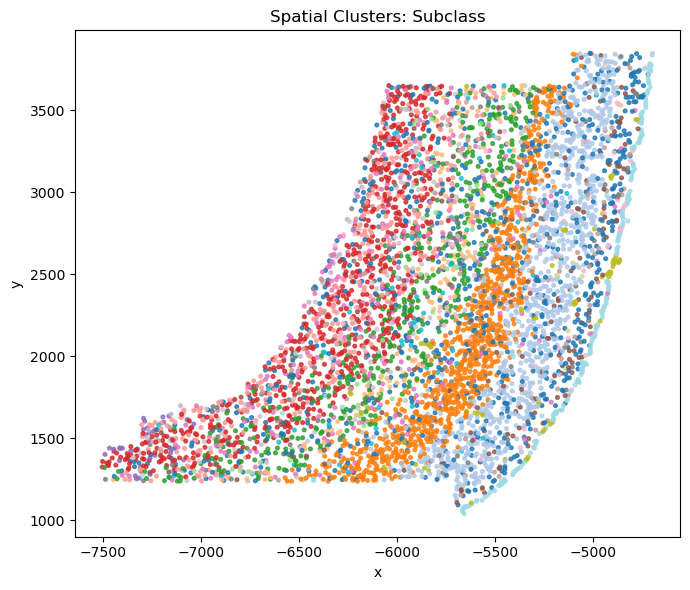

In [4]:
x = sp_integrated.obs["centroid_x"]
y_coord = sp_integrated.obs["centroid_y"]
y = sp_integrated.obs["subclass"]

cluster_codes = pd.Series(y).astype('category').cat.codes.to_numpy()
plt.figure(figsize=(7,6))
plt.scatter(x, y_coord, c=cluster_codes, cmap='tab20', s=7, alpha=0.8)
plt.title(f"Spatial Clusters: Subclass")
plt.xlabel("x")
plt.ylabel("y")
plt.tight_layout()
# plt.savefig("../data/ensemble_input/spatial_subclass.png")
# plt.close()

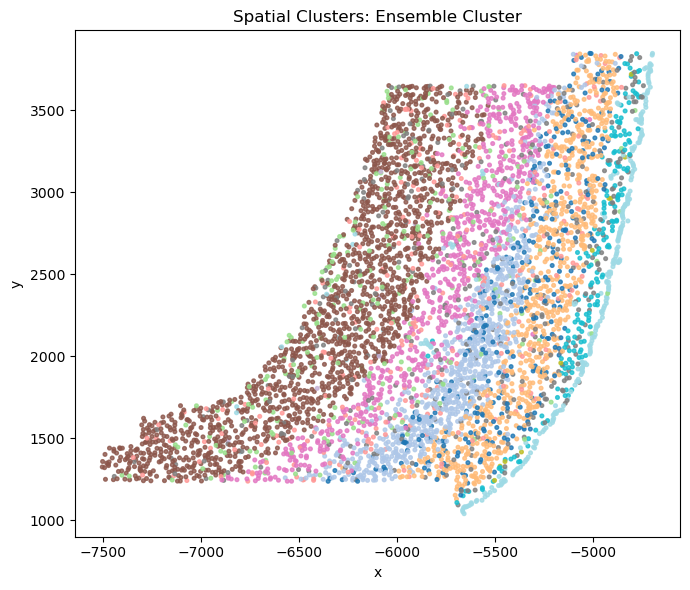

In [8]:
x = sp_integrated.obs["centroid_x"]
y_coord = sp_integrated.obs["centroid_y"]
y = sp_integrated.obs["ensemble_cluster"]

cluster_codes = pd.Series(y).astype('category').cat.codes.to_numpy()
plt.figure(figsize=(7,6))
plt.scatter(x, y_coord, c=cluster_codes, cmap='tab20', s=7, alpha=0.8)
plt.title(f"Spatial Clusters: Ensemble Cluster")
plt.xlabel("x")
plt.ylabel("y")
plt.tight_layout()

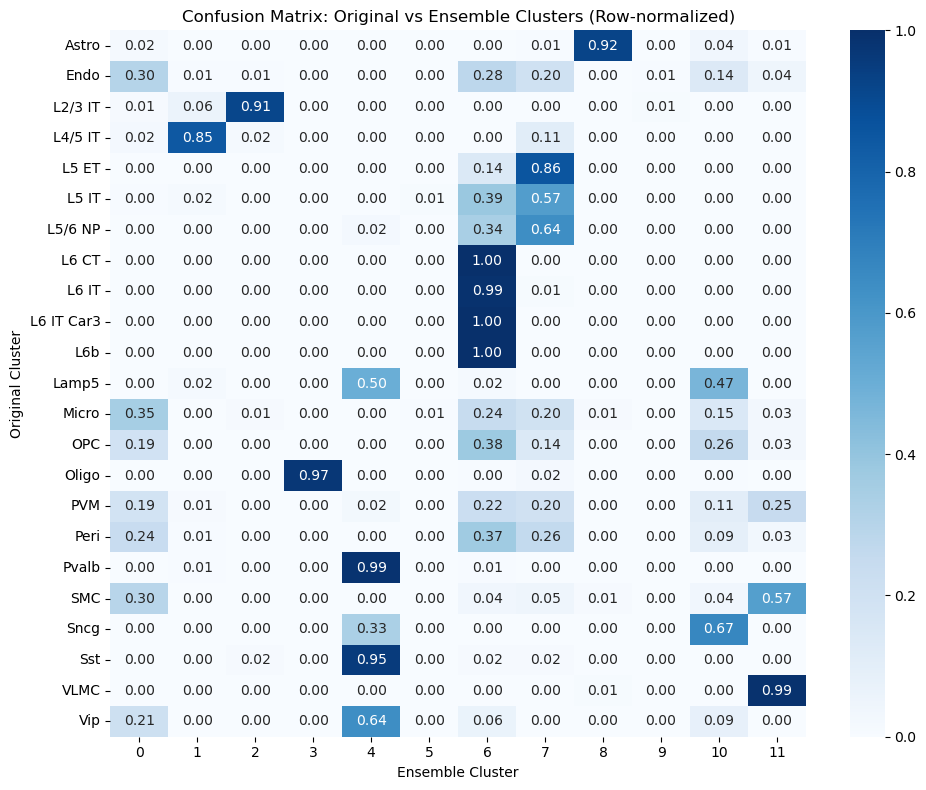

In [5]:
# Create confusion matrix
# Row-normalize data for better visualization

confusion_matrix = pd.crosstab(sp_integrated.obs['subclass'], sp_integrated.obs['ensemble_cluster'], rownames=['Original Cluster'], colnames=['Ensemble Cluster'])
confusion_matrix_normalized = confusion_matrix.div(confusion_matrix.sum(axis=1), axis=0)
plt.figure(figsize=(10,8))
sns.heatmap(confusion_matrix_normalized, annot=True, fmt='.2f', cmap='Blues')
plt.title("Confusion Matrix: Original vs Ensemble Clusters (Row-normalized)")
plt.ylabel("Original Cluster")
plt.xlabel("Ensemble Cluster")
plt.tight_layout()